# Build and sample a quantum circuit

This is Notebook 1 for the SC26 tutorial.
We will describe a small experiment in Qiskit, predict its outcomes, and sample it locally.

:::{admonition} Your turn
:class: tip

Start with a fresh kernel and run the cells in order.
:::

This notebook uses the same Python 3.15 environment as the rest of the tutorial.

In [1]:
import numpy as np
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_distribution

## Build a Bell circuit

:::{admonition} Your turn
:class: tip

Apply a Hadamard gate to qubit 0, then a controlled-X gate from qubit 0 to qubit 1.
:::

Starting from $|00\rangle$, this prepares $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$.

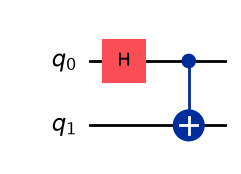

In [2]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.draw("mpl")

:::{admonition} Your turn
:class: tip

Before running the simulation, predict which bitstrings can occur.
:::

## Exact probabilities

Qiskit's statevector simulator computes all amplitudes.
It does a classical calculation of the ideal circuit, not a readout of an actual quantum device's complete state.

In [3]:
state = Statevector.from_instruction(bell)
probabilities = state.probabilities_dict()

print(f"Probability of measuring 00: {probabilities['00']}")
print(f"Probability of measuring 11: {probabilities['11']}")

Probability of measuring 00: 0.4999999999999999
Probability of measuring 11: 0.4999999999999999


## Add measurements and take shots

:::{admonition} Your turn
:class: tip

Copy the circuit and add terminal measurements to show the experiment we would submit to a device.
:::

Each shot yields one bitstring, and a histogram counts how often each bitstring occurs.

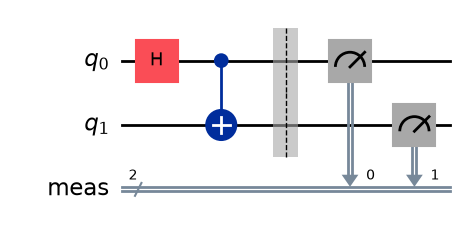

In [4]:
measured = bell.copy()
measured.measure_all()
measured.draw("mpl")

:::{admonition} Your turn
:class: tip

For this first notebook, sample directly from the statevector.
:::

The measurement
mapping is the one added by `measure_all()`. QDMI job submission comes later.

Number of shots resulting in 00: 495
Number of shots resulting in 11: 529


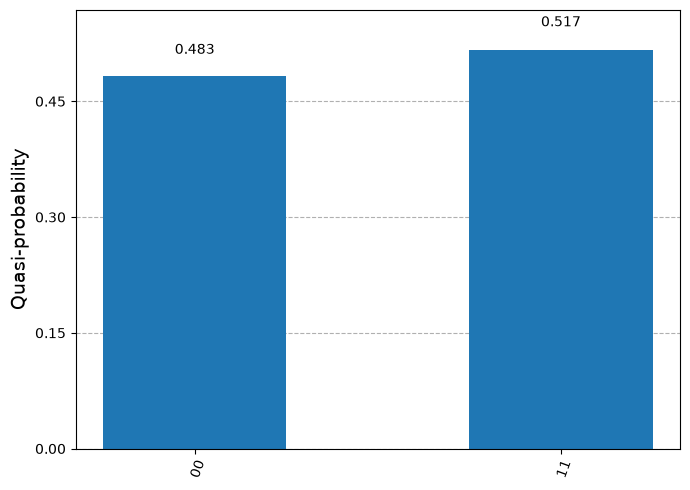

In [5]:
shots = 1024
counts = state.sample_counts(shots)

print(f"Number of shots resulting in 00: {counts['00']}")
print(f"Number of shots resulting in 11: {counts['11']}")
plot_distribution(counts)

:::{admonition} Your turn
:class: tip

Change `shots` to 32, then 8192.
The probabilities remain the same.
What changes in the histogram?
:::

## Exercise: Extend the circuit to three qubits

:::{admonition} Your turn
:class: tip

Prepare $(|000\rangle+|111\rangle)/\sqrt{2}$, a three-qubit GHZ state.
Start from the two-qubit circuit and extend the controlled-X chain.

Use the cell below for your solution, then run the check.
A solution is available in the collapsed section.
:::

:::{dropdown} Show a solution

```python
ghz = QuantumCircuit(3)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(1, 2)
```
:::

In [6]:
# Replace None with your three-qubit circuit
ghz = None

In [7]:
if ghz is None:
    print("Add your circuit in the previous cell and rerun this check.")
else:
    success = ghz.num_qubits == 3
    assert success, "The circuit must have three qubits."

    ghz_state = Statevector.from_instruction(ghz)
    expected = np.array([0.5, 0, 0, 0, 0, 0, 0, 0.5])
    success = np.allclose(ghz_state.probabilities(), expected)
    assert success, "The circuit does not produce the expected probabilities."

    expected_state = np.array([1 / np.sqrt(2), 0, 0, 0, 0, 0, 0, 1 / np.sqrt(2)], dtype=complex)
    success = ghz_state.equiv(Statevector(expected_state))
    assert success, "The circuit does not produce the expected state."

    display(ghz.draw("mpl"))
    display(plot_distribution(ghz_state.probabilities_dict()))

Add your circuit in the previous cell and rerun this check.
